In [61]:
import pandas as pd 
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
import joblib
df = pd.read_csv("../mocktest.csv",encoding="utf-8")
df['max_price'] = df['max_price'].fillna(df['max_price'].median())
df['min_price'] = df['min_price'].fillna(df['min_price'].median())
df['gender'] = df['gender'].fillna("NULL")
df['message'] = df['message'].fillna("NULL")
df['comment'] = df['comment'].fillna("NULL")
df['deviceType'] = df['deviceType'].fillna("NULL")
df['categories'] = df['categories'].fillna("NULL")
df['contents'] = df['contents'].fillna("NULL")



numerical_features = df.select_dtypes(include=['float64', 'int64']).columns

categorical_features = df.select_dtypes(include=['object']).columns

ss = StandardScaler()
ohe = OneHotEncoder(handle_unknown='ignore')
preprocessor = ColumnTransformer(
    transformers=[
        ('num', ss, numerical_features),
        ('cat', ohe, categorical_features)
    ]
)

for n_clusters in [2,3,5]:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('kmeans', kmeans)])
    pipeline.fit(df)
    df[f'cluster_{n_clusters}'] = pipeline.predict(df)
    joblib.dump(pipeline, f'kmeans_{n_clusters}segment.pkl')


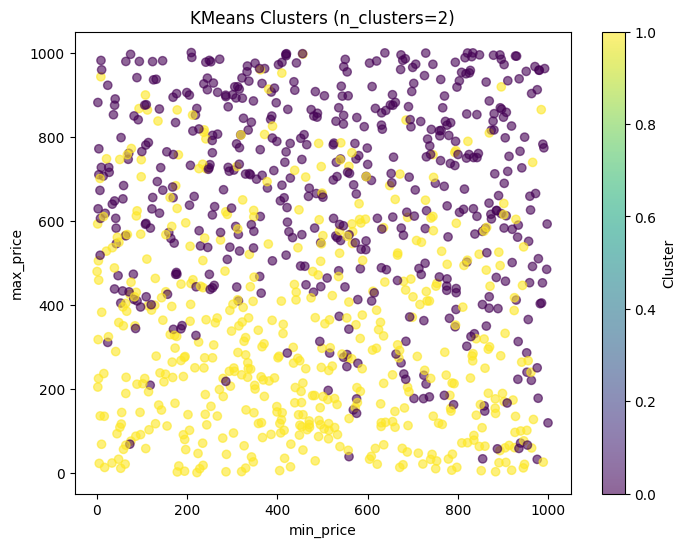

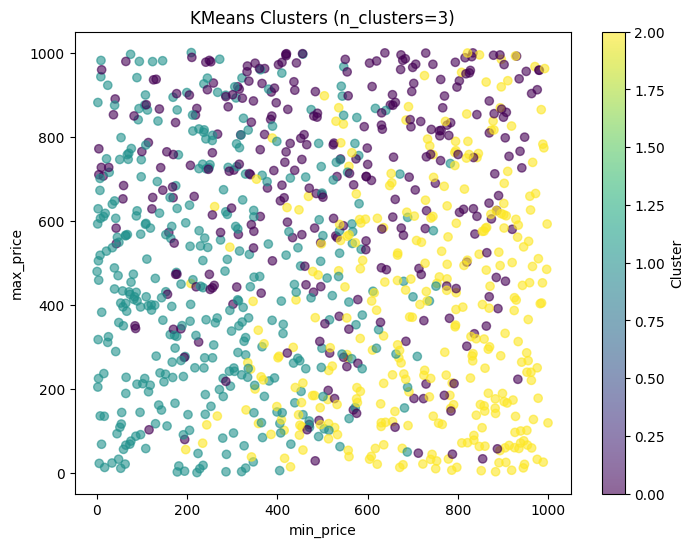

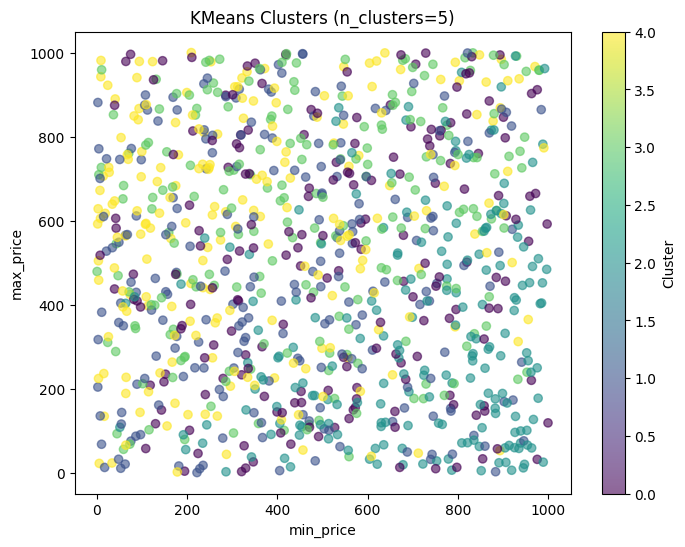

In [55]:
import matplotlib.pyplot as plt

for n_clusters in [2, 3, 5]:
    pipeline = joblib.load(f'kmeans_{n_clusters}segment.pkl')
    # Use the original features for plotting
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(
        df['min_price'],
        df['max_price'],
        c=df[f'cluster_{n_clusters}'],
        cmap='viridis',
        alpha=0.6
    )
    plt.xlabel('min_price')
    plt.ylabel('max_price')
    plt.title(f'KMeans Clusters (n_clusters={n_clusters})')
    plt.colorbar(scatter, label='Cluster')
    plt.show()


In [ ]:
df

,sessionID,pageID,categories,contents,createdAt,date,pageDuration,title,updatedAt,url,...,comment,message,min_price,gender,max_price,createdAt_form,updatedAt_form,cluster_2,cluster_3,cluster_5
0,140def60-4a8a-4931-9510-8cdac22fa981,2d5e6da9-c842-4862-9ef6-33970f58dcff,error: undefined method `first' for nil:NilClass,decorations,12/3/2022,886627.89,229,Rev,5/5/2022,https://toplist.cz/lacinia/nisi/venenatis/tris...,...,"Duis bibendum, felis sed interdum venenatis, t...",Curabitur gravida nisi at nibh. In hac habitas...,854.63,Female,400.54,5/24/2022,12/24/2022,0,2,2
1,dd0a2c09-c009-4d13-bd03-6f9014fbdbb1,dc41aa8f-92c5-434d-9203-f32b46944bbc,error: undefined method `first' for nil:NilClass,books,11/15/2022,896699.09,765,Mrs,1/14/2022,http://msn.com/tellus/in/sagittis.js?pede=posu...,...,Curabitur convallis. Duis consequat dui nec ni...,In congue. Etiam justo. Etiam pretium iaculis ...,835.66,Bigender,89.01,3/13/2022,2/15/2022,1,2,1
2,9b5f7bf4-61cc-49b5-ac60-0fc4980b7b54,858b970f-cf45-4495-9d58-8176776f0772,error: undefined method `first' for nil:NilClass,office supplies,11/21/2022,235355.97,94,Ms,9/22/2022,http://tmall.com/donec/dapibus/duis/at/velit.j...,...,"Donec vitae nisi. Nam ultrices, libero non mat...",Nullam porttitor lacus at turpis. Donec posuer...,16.67,Female,134.63,2/22/2022,6/1/2022,1,1,4
3,a6989147-befd-4fe9-89a6-aa2782fb0247,a32c937e-0c9e-4e82-b85c-c7aa0357f765,error: undefined method `first' for nil:NilClass,pet supplies,2/20/2022,142421.51,571,Rev,4/10/2022,http://howstuffworks.com/quis/turpis.json?mass...,...,"Lorem ipsum dolor sit amet, consectetuer adipi...",Maecenas ut massa quis augue luctus tincidunt....,782.58,Male,184.47,7/11/2022,1/16/2022,1,2,0
4,7ccbfcc8-1b38-4247-9949-014be3ef924a,589cdef6-c0f1-4584-9328-c78e65b6267b,error: undefined method `first' for nil:NilClass,decorations,1/10/2022,364992.90,418,Ms,6/19/2022,https://technorati.com/porttitor/id.aspx?morbi...,...,Maecenas rhoncus aliquam lacus. Morbi quis tor...,Duis bibendum. Morbi non quam nec dui luctus r...,556.55,Non-binary,274.00,5/18/2022,6/30/2022,1,2,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,76920533-9de2-459b-817f-654fe0f01d16,8bce2ba8-da7c-4e91-8335-ebefa0fccc17,error: undefined method `first' for nil:NilClass,tools,9/16/2022,116018.88,142,Dr,7/4/2022,https://dedecms.com/in/porttitor/pede/justo.pn...,...,Nullam sit amet turpis elementum ligula vehicu...,Sed ante. Vivamus tortor. Duis mattis egestas ...,39.56,Female,874.63,9/8/2022,3/17/2022,0,1,0
996,b9e6bd75-b73d-4494-927b-bfff0d9bcf0d,0dacfe56-717d-4650-ba89-9332809494e9,error: undefined method `first' for nil:NilClass,office supplies,8/19/2022,291526.54,481,Dr,2/15/2022,http://whitehouse.gov/quisque/id/justo/sit/ame...,...,Mauris sit amet eros. Suspendisse accumsan tor...,Cras non velit nec nisi vulputate nonummy. Mae...,453.71,Male,167.27,6/25/2022,5/22/2022,1,2,0
997,44e2f8bf-9f93-48d8-b62f-6ea3d6163349,79a94c5a-db08-4909-bfb9-a8212f2659c6,error: undefined method `first' for nil:NilClass,toys,11/28/2022,502285.67,169,Mrs,8/21/2022,http://hao123.com/suspendisse/potenti/cras.png...,...,"Nunc nisl. Duis bibendum, felis sed interdum v...","Proin eu mi. Nulla ac enim. In tempor, turpis ...",975.95,Male,249.92,9/3/2022,12/5/2022,0,2,2
998,a08c989f-cce5-4a19-8c92-f34d05726f99,80f7f925-758f-4155-80ce-836c57807b46,error: undefined method `first' for nil:NilClass,pet supplies,7/13/2022,773101.90,574,Honorable,10/25/2022,https://reference.com/nunc/commodo/placerat.ht...,...,Curabitur gravida nisi at nibh.,Aenean fermentum. Donec ut mauris eget massa t...,629.10,Male,164.13,3/30/2022,2/4/2022,1,2,2


In [63]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

for n_clusters in [2, 3, 5]:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('pca', pca),
        ('kmeans', kmeans)
    ])
    pipeline.fit(df)
    xpca = pipeline.named_steps['pca'].transform(
        pipeline.named_steps['preprocessor'].transform(df)
    )
    df[f"pca1_{n_clusters}"] = xpca[:, 0]
    df[f"pca2_{n_clusters}"] = xpca[:, 1]
    df[f'cluster_{n_clusters}'] = pipeline.predict(df)
    joblib.dump(pipeline, f'kmeans_{n_clusters}segment.pkl')


In [57]:
df

,sessionID,pageID,categories,contents,createdAt,date,pageDuration,title,updatedAt,url,...,updatedAt_form,cluster_2,cluster_3,cluster_5,pca1_2,pca2_2,pca1_3,pca2_3,pca1_5,pca2_5
0,140def60-4a8a-4931-9510-8cdac22fa981,2d5e6da9-c842-4862-9ef6-33970f58dcff,error: undefined method `first' for nil:NilClass,decorations,12/3/2022,886627.89,229,Rev,5/5/2022,https://toplist.cz/lacinia/nisi/venenatis/tris...,...,12/24/2022,1,2,3,-1.015016,-1.248582,-1.015016,-1.248582,-1.015016,-1.248582
1,dd0a2c09-c009-4d13-bd03-6f9014fbdbb1,dc41aa8f-92c5-434d-9203-f32b46944bbc,error: undefined method `first' for nil:NilClass,books,11/15/2022,896699.09,765,Mrs,1/14/2022,http://msn.com/tellus/in/sagittis.js?pede=posu...,...,2/15/2022,1,1,1,-0.179115,-0.653939,-0.179115,-0.653939,-0.179115,-0.653939
2,9b5f7bf4-61cc-49b5-ac60-0fc4980b7b54,858b970f-cf45-4495-9d58-8176776f0772,error: undefined method `first' for nil:NilClass,office supplies,11/21/2022,235355.97,94,Ms,9/22/2022,http://tmall.com/donec/dapibus/duis/at/velit.j...,...,6/1/2022,0,0,0,1.099601,0.614872,1.099601,0.614872,1.099601,0.614872
3,a6989147-befd-4fe9-89a6-aa2782fb0247,a32c937e-0c9e-4e82-b85c-c7aa0357f765,error: undefined method `first' for nil:NilClass,pet supplies,2/20/2022,142421.51,571,Rev,4/10/2022,http://howstuffworks.com/quis/turpis.json?mass...,...,1/16/2022,1,1,1,0.327515,-1.243137,0.327515,-1.243137,0.327515,-1.243137
4,7ccbfcc8-1b38-4247-9949-014be3ef924a,589cdef6-c0f1-4584-9328-c78e65b6267b,error: undefined method `first' for nil:NilClass,decorations,1/10/2022,364992.90,418,Ms,6/19/2022,https://technorati.com/porttitor/id.aspx?morbi...,...,6/30/2022,1,2,3,-0.809511,-0.194032,-0.809511,-0.194032,-0.809511,-0.194032
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,76920533-9de2-459b-817f-654fe0f01d16,8bce2ba8-da7c-4e91-8335-ebefa0fccc17,error: undefined method `first' for nil:NilClass,tools,9/16/2022,116018.88,142,Dr,7/4/2022,https://dedecms.com/in/porttitor/pede/justo.pn...,...,3/17/2022,0,0,4,1.686875,0.545508,1.686875,0.545508,1.686875,0.545508
996,b9e6bd75-b73d-4494-927b-bfff0d9bcf0d,0dacfe56-717d-4650-ba89-9332809494e9,error: undefined method `first' for nil:NilClass,office supplies,8/19/2022,291526.54,481,Dr,2/15/2022,http://whitehouse.gov/quisque/id/justo/sit/ame...,...,5/22/2022,1,1,1,0.360143,-0.417829,0.360143,-0.417829,0.360143,-0.417829
997,44e2f8bf-9f93-48d8-b62f-6ea3d6163349,79a94c5a-db08-4909-bfb9-a8212f2659c6,error: undefined method `first' for nil:NilClass,toys,11/28/2022,502285.67,169,Mrs,8/21/2022,http://hao123.com/suspendisse/potenti/cras.png...,...,12/5/2022,1,2,3,-1.397470,-0.669331,-1.397470,-0.669331,-1.397470,-0.669331
998,a08c989f-cce5-4a19-8c92-f34d05726f99,80f7f925-758f-4155-80ce-836c57807b46,error: undefined method `first' for nil:NilClass,pet supplies,7/13/2022,773101.90,574,Honorable,10/25/2022,https://reference.com/nunc/commodo/placerat.ht...,...,2/4/2022,1,2,3,-0.784546,-0.853663,-0.784546,-0.853663,-0.784546,-0.853663


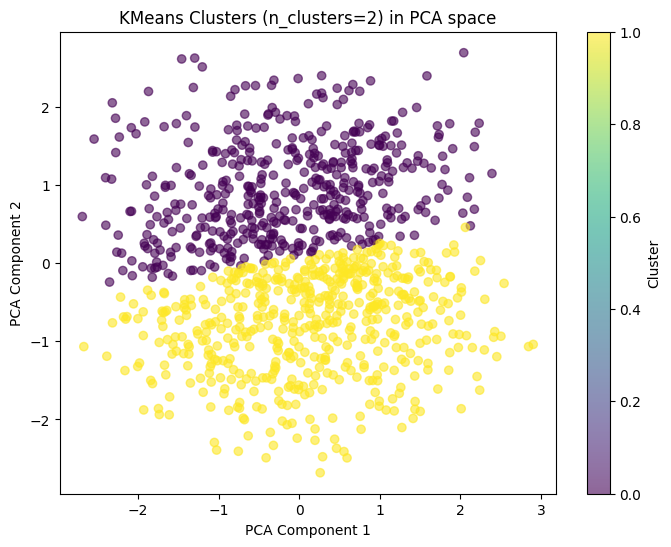

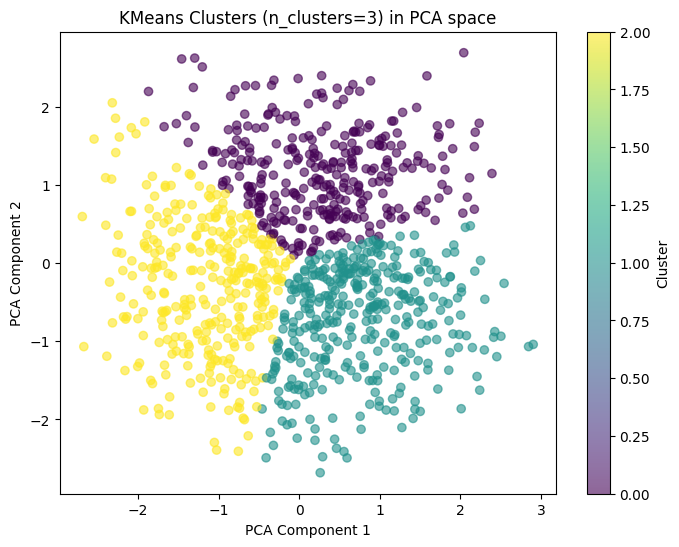

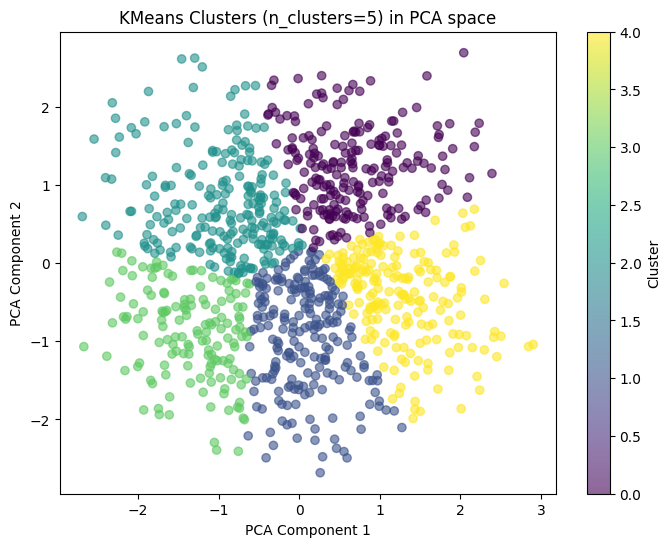

In [ ]:
import matplotlib.pyplot as plt

for n_clusters in [2, 3, 5]:
    xpca = df[[f'pca1_{n_clusters}', f'pca2_{n_clusters}']].values
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(
        xpca[:, 0],
        xpca[:, 1],
        c=df[f'cluster_{n_clusters}'],
        cmap='viridis',
        alpha=0.6
    )
    plt.xlabel('PCA Component 1')
    plt.ylabel('PCA Component 2')
    plt.title(f'KMeans Clusters (n_clusters={n_clusters}) in PCA space')
    plt.colorbar(scatter, label='Cluster')
    plt.show()